# Customer Churn Prediction & Model Evaluation
**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)  
**Models:** Logistic Regression & K-Nearest Neighbors (KNN)

---

## 1. Problem Statement
Customer churn occurs when a customer cancels or discontinues their subscription or service. In the telecom industry, acquiring a new customer is substantially more expensive than retaining an existing one. 

The goal of this analysis is to:
1. Identify the key behavioral and demographic drivers of customer churn.
2. Build and compare classification models to predict which customers are at risk of churning.
3. Formulate actionable business recommendations to improve customer retention.

This is a **binary classification** problem:
- `1` (Yes): The customer churned.
- `0` (No): The customer stayed.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

# Styling and reproducibility
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

# Ensure figures folder exists
os.makedirs('figures', exist_ok=True)
def save(name): 
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')


## 2. Load the Dataset


In [2]:
df = pd.read_csv('telco.csv')
print('Shape:', df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Exploratory Data Analysis (EDA)

Let's start by looking at summary statistics and examining the distribution of customer churn.


In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


Churn
No     5174
Yes    1869
Name: count, dtype: int64 
 Churn
No     73.5 %
Yes    26.5 %
Name: count, dtype: str


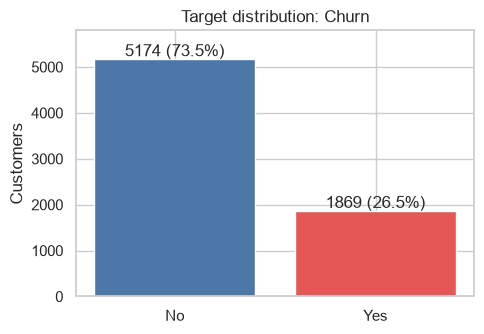

In [5]:
# Target variable distribution
counts = df['Churn'].value_counts()
print(counts, '\n', (counts/len(df)*100).round(1).astype(str)+' %')

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=['#4C78A8', '#E45756'])

for i, v in enumerate(counts.values):
    ax.text(i, v + 60, f'{v} ({v/len(df):.1%})', ha='center')

ax.set_title('Target distribution: Churn')
ax.set_ylabel('Customers')
ax.set_ylim(0, counts.max() * 1.12)

save('01_target_distribution')
plt.show()


Only about 26.5% of customers in the dataset churned (~1 in 4), which shows moderate **class imbalance**. 

Because the majority class is non-churners (~73.5%), accuracy by itself will be misleading: a dummy model predicting "No Churn" for every single person would achieve 73.5% accuracy while completely failing to flag churning customers. As a result, we will evaluate models primarily on **Precision, Recall, and F1-score**.


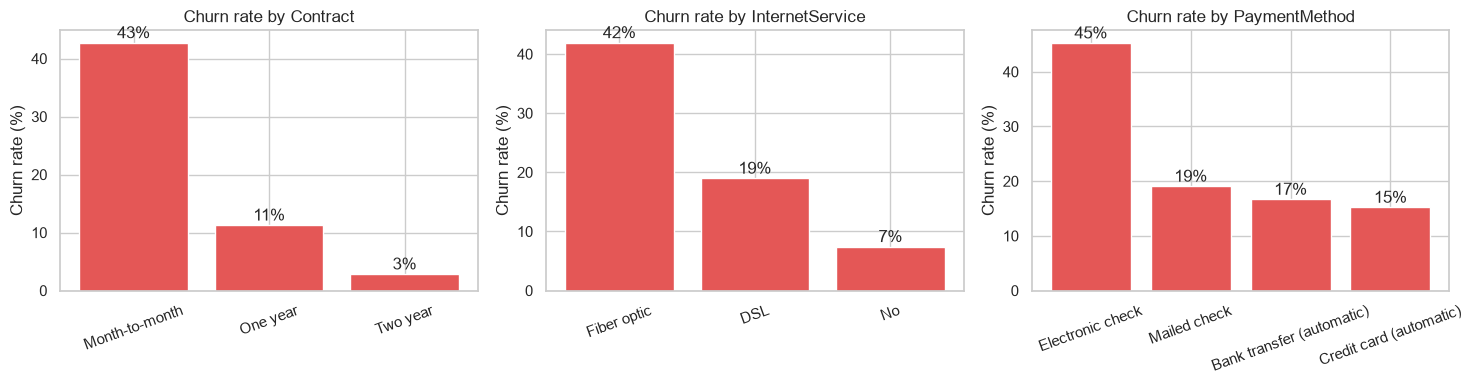

In [6]:
# Churn rate across key categorical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    rate = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values(ascending=False)
    ax.bar(rate.index, rate.values, color='#E45756')
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate (%)')
    ax.tick_params(axis='x', rotation=20)
    
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f'{v:.0f}%', ha='center')

save('02_churn_by_category')
plt.show()


A few immediate takeaways from these categorical breakdowns:
- **Contract:** Month-to-month subscribers have by far the highest churn rate (~43%), whereas 1-year and 2-year contract holders rarely churn.
- **Internet Service:** Fiber-optic customers churn at much higher rates (~42%) than DSL or No-Internet customers.
- **Payment Method:** Customers paying via electronic check churn significantly more (~45%) than those on automated payment options (credit card or bank transfer).


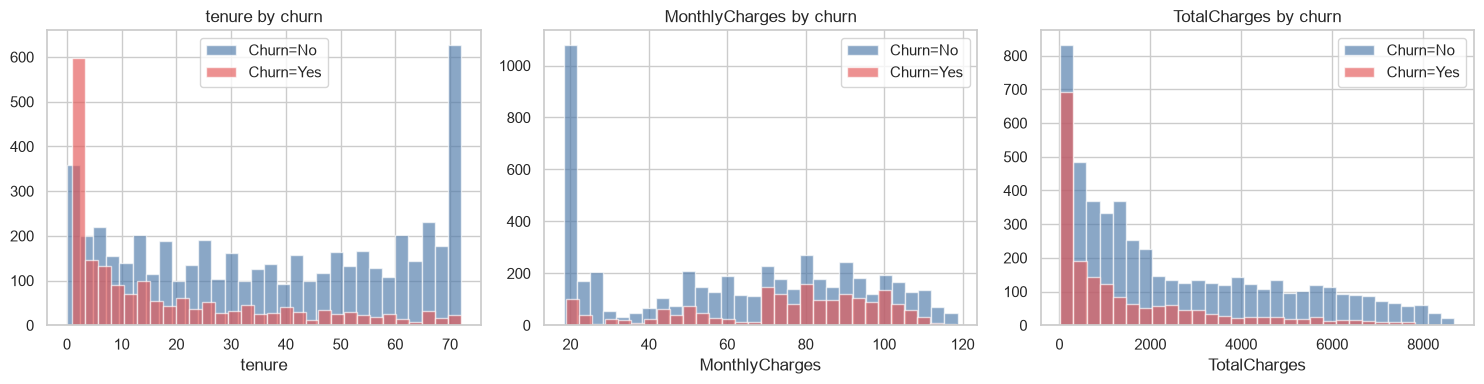

In [7]:
# TotalCharges is stored as text because some cells are blank -> convert, blanks become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    for lab, c in [('No', '#4C78A8'), ('Yes', '#E45756')]:
        ax.hist(df.loc[df.Churn == lab, col].dropna(), bins=30, alpha=0.65, label=f'Churn={lab}', color=c)
    ax.set_title(f'{col} by churn')
    ax.set_xlabel(col)
    ax.legend()

save('03_numeric_distributions')
plt.show()


Observations from numerical feature distributions:
- **Tenure:** Churn is heavily concentrated in the first few months. The danger zone is early in the customer lifecycle.
- **Monthly Charges:** Churning customers tend to have higher monthly charges (peaking around $70–$100).
- **Total Charges:** Most churners have low cumulative total charges simply because they leave before accumulating substantial tenure.


## 4. Data Cleaning & Handling Missing Values


In [8]:
# Check for null values
missing = df.isnull().sum()
print(missing[missing > 0])

print('\nRows with missing TotalCharges (all have tenure = 0, i.e. brand-new customers):')
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].head()


TotalCharges    11
dtype: int64

Rows with missing TotalCharges (all have tenure = 0, i.e. brand-new customers):


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No


In [9]:
# TotalCharges has 11 missing values (0.16%).
# Imputing with the median is robust to the right-skewed distribution.
median_tc = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_tc)
print('Median used:', median_tc, '| missing now:', df.isnull().sum().sum())

# Drop customerID since it is an arbitrary identifier
df = df.drop(columns='customerID')

# Check duplicate rows
print('Rows identical in every feature:', df.duplicated().sum(), 
      '(kept: after removing the ID they are different customers with similar plans)')


Median used: 1397.475 | missing now: 0
Rows identical in every feature: 22 (kept: after removing the ID they are different customers with similar plans)


Since missing values account for only 11 rows out of 7,043, median imputation preserves all observations without distorting the overall distribution. The `customerID` column has no predictive utility and was dropped.


## 5. Feature Encoding

Next, we encode binary and multi-class categorical columns into numerical values suitable for machine learning algorithms.


In [10]:
# Binary Yes/No columns -> label encoding (0/1); multi-category columns -> one-hot encoding
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
df['gender'] = (df['gender'] == 'Male').astype(int)

yes_no = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for c in yes_no:
    df[c] = (df[c] == 'Yes').astype(int)

multi = [c for c in df.select_dtypes('object').columns]
print('One-hot encoding:', multi)

df_enc = pd.get_dummies(df, columns=multi, drop_first=True, dtype=int)
print('Shape after encoding:', df_enc.shape)
df_enc.head()


One-hot encoding: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Shape after encoding: (7043, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


We use `drop_first=True` to prevent multicollinearity (the dummy variable trap), which ensures that linear models like Logistic Regression remain stable and well-conditioned.


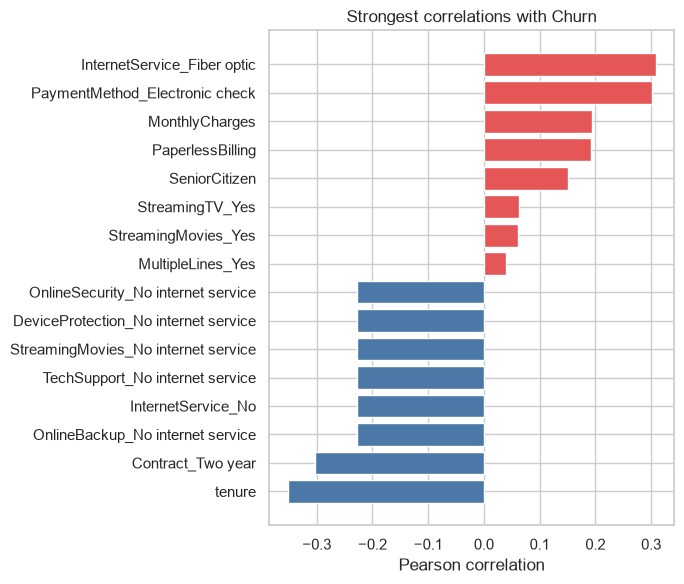

In [11]:
# Correlation of every feature with churn
corr = df_enc.corr()['Churn'].drop('Churn').sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])

fig, ax = plt.subplots(figsize=(7, 6))
colors = ['#4C78A8' if v < 0 else '#E45756' for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.set_title('Strongest correlations with Churn')
ax.set_xlabel('Pearson correlation')

save('04_correlation_with_churn')
plt.show()


## 6. Train/Test Split & Feature Scaling


In [12]:
X = df_enc.drop(columns='Churn')
y = df_enc['Churn']

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

# Scale numerical columns (fit on training data ONLY to prevent leakage)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler().fit(X_train[num_cols])

X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols]  = scaler.transform(X_test[num_cols])

X_train_s[num_cols].describe().loc[['mean', 'std']].round(3)


Train: (5634, 30) | Test: (1409, 30)
Churn rate train/test: 0.265 0.265


,tenure,MonthlyCharges,TotalCharges
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


We use a **stratified split** to ensure both sets retain the exact same 26.5% churn proportion.

The `StandardScaler` is fitted solely on `X_train` and then used to transform `X_test`. This strictly prevents **data leakage** from the test set into training. Feature scaling is particularly vital for distance-based models like KNN, where large numeric values (e.g., `TotalCharges` up to $8,000) would otherwise dominate the Euclidean distance calculation.


## 7. Model Training & Hyperparameter Tuning

We compare two models:
1. **Logistic Regression:** A linear classifier that models log-odds, offering fast training and interpretable weights.
2. **K-Nearest Neighbors (KNN):** A non-parametric distance-based classifier. We tune the neighbor count $K$ using 5-fold cross-validation on the training set.


In [13]:
# Choose K for KNN with 5-fold CV on the training set (never touching the test set)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ks = list(range(1, 52, 2))
cv_scores = [cross_val_score(KNeighborsClassifier(k), X_train_s, y_train, cv=cv, scoring='f1').mean() for k in ks]

best_k = ks[int(np.argmax(cv_scores))]
print('Best K by CV F1:', best_k, '| CV F1 =', round(max(cv_scores), 4))

lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)


Best K by CV F1: 35 | CV F1 = 0.6088


## 8. Model Evaluation & Comparison


In [14]:
def evaluate(name, model):
    preds = model.predict(X_test_s)
    probs = model.predict_proba(X_test_s)[:, 1]
    
    return {
        'Model': name, 
        'Accuracy': accuracy_score(y_test, preds), 
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds), 
        'F1-score': f1_score(y_test, preds),
        'ROC-AUC': roc_auc_score(y_test, probs)
    }

results = pd.DataFrame([
    evaluate('Logistic Regression', lr), 
    evaluate(f'KNN (k={best_k})', knn)
]).set_index('Model').round(4)

results.to_csv('evaluation_summary.csv')
results


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
KNN (k=35),0.7942,0.6173,0.5909,0.6038,0.8338


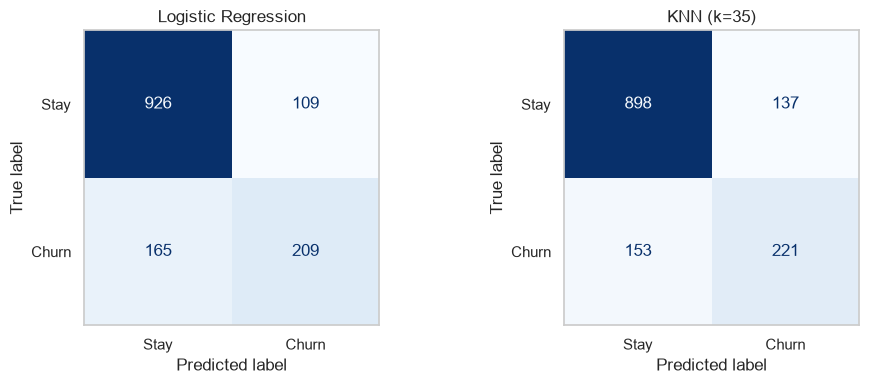

Logistic Regression: TN=926 FP=109 FN=165 TP=209
KNN (k=35): TN=898 FP=137 FN=153 TP=221


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
model_list = [('Logistic Regression', lr), (f'KNN (k={best_k})', knn)]

for ax, (name, m) in zip(axes, model_list):
    cm = confusion_matrix(y_test, m.predict(X_test_s))
    disp = ConfusionMatrixDisplay(cm, display_labels=['Stay', 'Churn'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    ax.grid(False)

save('05_confusion_matrices')
plt.show()

for name, m in model_list:
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test_s)).ravel()
    print(f'{name}: TN={tn} FP={fp} FN={fn} TP={tp}')


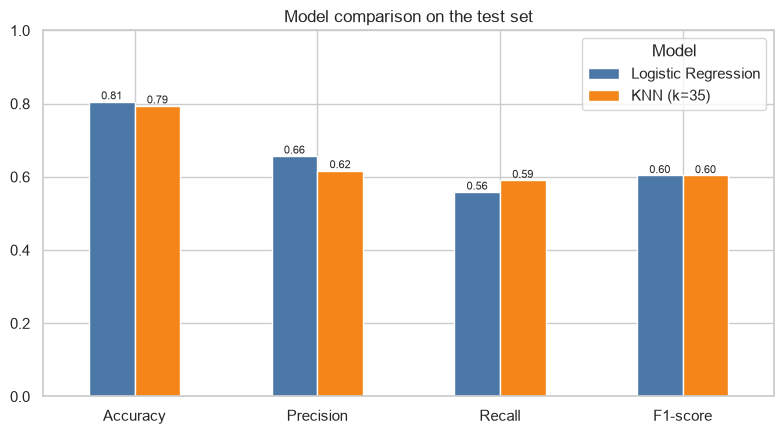

In [16]:
ax = results[['Accuracy', 'Precision', 'Recall', 'F1-score']].T.plot(
    kind='bar', figsize=(8, 4.5), color=['#4C78A8', '#F58518'], rot=0
)
ax.set_title('Model comparison on the test set')
ax.set_ylim(0, 1)

for c in ax.containers: 
    ax.bar_label(c, fmt='%.2f', fontsize=8)

save('06_model_comparison')
plt.show()


### Key Metric Takeaways

- Both models yield nearly identical F1-scores (**~0.604**).
- **Logistic Regression** achieves higher Precision (65.7% vs. 61.7%) and higher ROC-AUC (0.842 vs. 0.834), leading to fewer false positives.
- **KNN** achieves slightly higher Recall (59.1% vs. 55.9%), catching a few additional churners at the cost of more false alarms.
- Both models still miss about 40% of churners under the default 0.5 decision threshold.


## 9. Diagnosing Overfitting vs. Underfitting


In KNN, the neighborhood size $K$ acts as the model complexity dial:
- **Small $K$ (e.g. $K=1$):** High complexity / high variance. The decision boundary tightly hugs every training point, leading to severe overfitting.
- **Large $K$:** Low complexity / high bias. The model averages over a huge neighborhood, resulting in an overly smooth boundary and underfitting.
- **Optimal $K$ ($K=35$):** Balances bias and variance to maximize generalization on unseen test data.


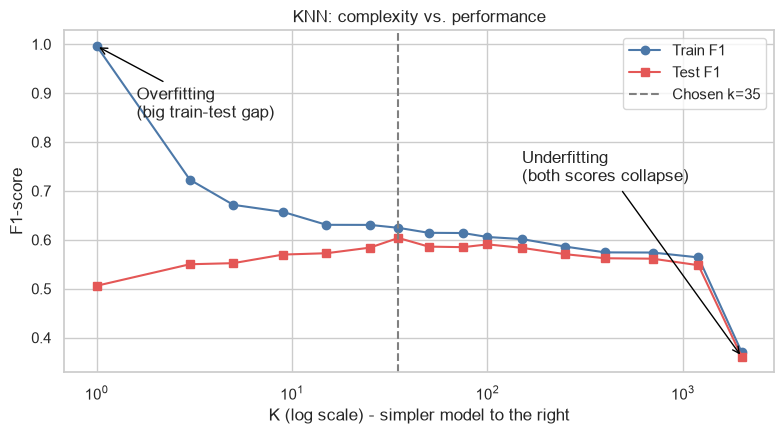

In [17]:
ks2 = [1, 3, 5, 9, 15, 25, 35, 50, 75, 100, 150, 250, 400, 700, 1200, 2000]
tr, te = [], []

for k in ks2:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    tr.append(f1_score(y_train, m.predict(X_train_s)))
    te.append(f1_score(y_test, m.predict(X_test_s)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.set_xscale('log')
ax.plot(ks2, tr, 'o-', label='Train F1', color='#4C78A8')
ax.plot(ks2, te, 's-', label='Test F1', color='#E45756')
ax.axvline(best_k, ls='--', color='gray', label=f'Chosen k={best_k}')

ax.annotate('Overfitting\n(big train-test gap)', xy=(ks2[0], tr[0]), xytext=(1.6, 0.85), 
            arrowprops=dict(arrowstyle='->', color='black'))
ax.annotate('Underfitting\n(both scores collapse)', xy=(ks2[-1], te[-1]), xytext=(150, 0.72), 
            arrowprops=dict(arrowstyle='->', color='black'))

ax.set_xlabel('K (log scale) - simpler model to the right')
ax.set_ylabel('F1-score')
ax.set_title('KNN: complexity vs. performance')
ax.legend()

save('07_overfitting_underfitting')
plt.show()


In [18]:
fit = pd.DataFrame({
    'Train Accuracy': [accuracy_score(y_train, m.predict(X_train_s)) for m in (lr, knn)],
    'Test Accuracy':  [accuracy_score(y_test,  m.predict(X_test_s))  for m in (lr, knn)],
    'Train F1': [f1_score(y_train, m.predict(X_train_s)) for m in (lr, knn)],
    'Test F1':  [f1_score(y_test,  m.predict(X_test_s))  for m in (lr, knn)]
}, index=['Logistic Regression', f'KNN (k={best_k})'])

fit['F1 gap (train-test)'] = fit['Train F1'] - fit['Test F1']
fit.round(4)


,Train Accuracy,Test Accuracy,Train F1,Test F1,F1 gap (train-test)
Logistic Regression,0.8055,0.8055,0.6000,0.6040,-0.0040
KNN (k=35),0.8101,0.7942,0.6246,0.6038,0.0207


## 10. Feature Importance & Model Interpretation

A key practical advantage of Logistic Regression is interpretability. Examining the learned coefficients reveals which factors most heavily push customer probabilities toward churning or staying.


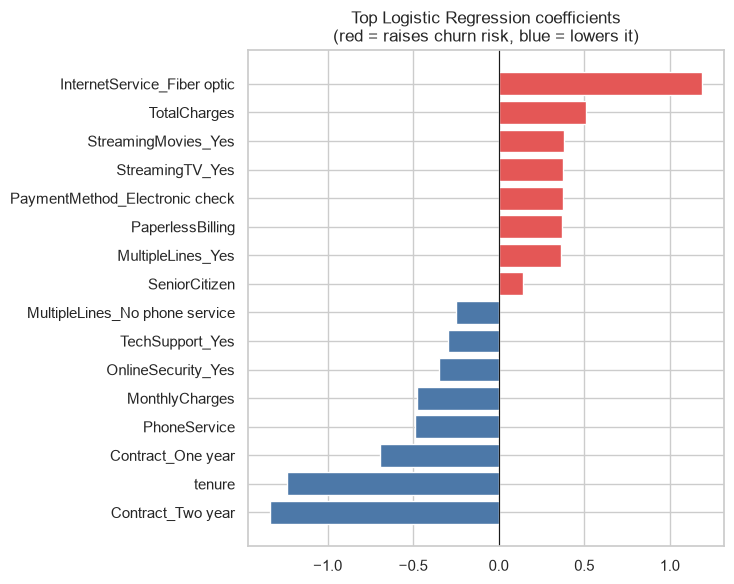

In [19]:
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])

fig, ax = plt.subplots(figsize=(7.5, 6))
bar_colors = ['#4C78A8' if v < 0 else '#E45756' for v in top.values]
ax.barh(top.index, top.values, color=bar_colors)
ax.set_title('Top Logistic Regression coefficients\n(red = raises churn risk, blue = lowers it)')
ax.axvline(0, color='k', lw=0.8)

save('08_lr_coefficients')
plt.show()


### Coefficient Interpretation
- **Strongest churn drivers (positive coefficients):** Fiber-optic internet service, electronic check payment, and paperless billing all associate with higher churn probability.
- **Strongest retention anchors (negative coefficients):** Two-year and one-year contracts, followed by longer tenure, significantly reduce churn risk.
- **Multicollinearity nuance:** Even though raw `MonthlyCharges` has positive correlation with churn in univariate EDA, its coefficient here is slightly negative because the service-specific dummies (e.g. Fiber optic) absorb much of the charge variance.


## 11. Addressing Class Imbalance (Class Weighting)

In customer churn, failing to identify an at-risk customer (false negative) is typically far more expensive than offering a small discount or retention perk to a customer who wasn't actually going to leave (false positive).

To increase sensitivity towards the churn class, we re-train Logistic Regression with `class_weight='balanced'`.


In [20]:
lr_bal = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE).fit(X_train_s, y_train)
p_bal = lr_bal.predict(X_test_s)
proba_bal = lr_bal.predict_proba(X_test_s)[:, 1]

bal_row = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test, p_bal),
    'Precision': precision_score(y_test, p_bal),
    'Recall': recall_score(y_test, p_bal),
    'F1-score': f1_score(y_test, p_bal),
    'ROC-AUC': roc_auc_score(y_test, proba_bal)
}], index=['Logistic Regression (balanced)']).round(4)

final = pd.concat([results, bal_row])
final.index.name = 'Model'
final.to_csv('evaluation_summary.csv')
final


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
KNN (k=35),0.7942,0.6173,0.5909,0.6038,0.8338
Logistic Regression (balanced),0.7388,0.5052,0.7834,0.6143,0.8417


By applying balanced class weights, **Recall jumps from 55.9% to 78.3%** — catching roughly 84 additional churning customers on the test set. Precision drops from 65.7% to 50.5%, which is a sensible business trade-off whenever the customer lifetime value (LTV) substantially exceeds the retention intervention cost.


## 12. Conclusions & Business Insights


In [21]:
best = results['F1-score'].idxmax()
print(f'Best baseline model by F1: {best}\n')
print(final.to_string())


Best baseline model by F1: Logistic Regression

                                Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                         
Logistic Regression               0.8055     0.6572  0.5588    0.6040   0.8421
KNN (k=35)                        0.7942     0.6173  0.5909    0.6038   0.8338
Logistic Regression (balanced)    0.7388     0.5052  0.7834    0.6143   0.8417


### Summary of Findings
1. **Core Churn Drivers:** Churn is heavily driven by **short tenure, month-to-month contracts, fiber-optic service, and electronic check billing**. Long-term contracts and longer tenure are strong retention anchors.
2. **Model Comparison:** 
   - Both baseline models achieve roughly equal test F1 (~0.604).
   - **Logistic Regression is the preferred model:** it requires minimal compute, shows virtually zero train-test generalization gap, and yields directly interpretable feature weights.
   - **KNN** is sensitive to the choice of $K$, exhibits higher variance, and is substantially slower at inference time.
3. **Imbalance Handling:** Default models miss roughly 40% of churners. Using balanced class weighting dramatically boosts recall to ~78.3%, capturing the majority of churning accounts.

### Business Recommendations
- **Incentivize Contract Migrations:** Offer targeted promotional discounts to transition month-to-month customers into 1-year or 2-year commitments.
- **Onboarding Retention Programs:** Focus proactive customer support during the first 6 months of customer tenure, which represents the highest-risk churn window.
- **Audit Fiber-Optic Quality & Pricing:** Investigate whether high fiber-optic churn stems from pricing issues, competitive promotional expirations, or technical dissatisfaction.
- **Encourage Automated Billing:** Incentivize customers using electronic checks to enroll in automated bank transfer or credit card autopay.
